[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/HumbertoDiego/AjustamentoBasicoIME/blob/main/09_modelo_combinado.ipynb)

# Ajustamento Básico - Modelos clássicos de ajustamento

**Maj Diego - 2° Semestre / 2026**

**Objetivos:**

1. Apresentar o Modelo Combinado/Geral/Implícito;
2. Apresentar a solução para a modelagem Combinada;
3. Apresentar a propagação de erros da modelagem Combinada.

**Referência:** Camil Gemael, Alvaro Muriel Lima Machado, Romualdo Wandresen (2015). *Introdução ao Ajustamento de Observações: Aplicações Geodésicas*. 2ª Ed., Curitiba, Ed. UFPR. $\rightarrow$ **Cap 8, 9, 10 e 11**

## O Problema

Existe uma classe de problemas em ajustamento em que certas **condições** precisam ser **exatamente satisfeitas**, porém os parâmetros e observações ajustadas aparecem juntos, as envolvendo simultaneamente.

**Exemplo:** Em poligonais circulares, onde a condição geométrica $((X_n - X_C )^2 + (Y_n- Y_C)^2 - r^2 = 0)$ não permite isolamento entre parâmetros $(X_C, Y_C, r)$ e observações $(X_n, Y_n)$.

## 1. Apresentar o Modelo Combinado

O **Modelo Combinado** é o caso mais geral dos modelos clássicos, pois envolve simultaneamente parâmetros desconhecidos e observações ajustadas. Sua forma funcional é

$$
F(X_a,L_a)=0.
$$

Ele é usado quando as equações do problema não permitem escrever diretamente todas as observações apenas em função dos parâmetros, nem apenas impor condições entre observações. Um exemplo típico é o ajustamento de uma circunferência quando as coordenadas dos pontos observados recebem correções e, ao mesmo tempo, são estimados o centro e o raio.

No caso linear, separamos a matriz de coeficientes só dos parâmetros $A$, a matriz de coeficientes só resíduos $B$ e a matriz de termos independentes $W$:

$$AX_a + BV +W = 0$$



### **1.1 O caso não linear**

Na $i$-ésima iteração, parte-se dos valores ajustados da iteração anterior, $X_a^{i-1}$ e $L_a^{i-1}=L^0+V^{i-1}$. Onde $X^0$ é proveninte de um "chute" inicial e $L^0$ é o vetor das observações iniciais. Procuram-se a correção $\Delta X^i$ dos parâmetros e o novo vetor de resíduos $V^i$, de modo que:

$$
X_a^i=X_a^{i-1}+ \Delta X^i, \qquad L_a^i=  L^0+V^i.
$$

A linearização de $F(X_a^i,L_a^i)=0$ em torno de $(X_a^{i-1},L_a^{i-1})$ fornece:

$$
\small F(X_a^i,L_a^i) = F(X_a^{i-1},L_a^{i-1})+ \underbrace{\left.\frac{\partial F}{\partial X_a}\right|_{X_a^{i-1},L_a^{i-1}}}_{A^i} (X_a^i-X_a^{i-1})+ \underbrace{\left.\frac{\partial F}{\partial L_a}\right|_{X_a^{i-1},L_a^{i-1}}}_{B^i} (L_a^i-L_a^{i-1})\approx 0,
$$

Como $L_a^i-L_a^{i-1}=L^0 + V^i - L_a^{i-1}$, obtém-se a forma linear do modelo combinado em cada iteração:

$$
\small A^i \Delta X^i+B^iV^i+W^i=0,
\qquad
W^i=F(X_a^{i-1},L_a^{i-1})+B^i(L^0-L_a^{i-1}).
$$


### **1.2 Redundância do modelo Combinado**

$$ \underbrace{{}_mA_n \ {}_nX_1}_{\text{Parâmetros}} + \underbrace{{}_mB_r \ {}_rV_1}_{\text{Observações}} + \underbrace{{}_mW_1}_{\text{Fechamento}} = 0$$

Para $m$ equações, $n$ parâmetros e $r$ valores observados.

O requisito para o modelo combinado funcionar é:

$$
r>m-n \\ 
(\text{qte de valores observados} > \text{graus de liberdade})
$$


### **1.3 Comparação Paramétrico - Combinado**

**Exemplo 01:** duas observações independentes $L_0=\begin{bmatrix}10.1 & 10.4\end{bmatrix}^T$ de uma mesma grandeza $x$:

$\text{Paramétrico:} \begin{cases} x = 10.1 \\  x = 10.4  \end{cases}  \rightarrow gl=2eq -1 par = 1  \rightarrow \begin{cases} x_a = 10.1 +v_1 \\  x_a = 10.4 +v_2  \end{cases}$

$\text{Combinado: } \begin{cases} x - 10.1 =0\\  x - 10.4 =0 \end{cases}  \rightarrow gl=2eq -1 par = 1  \rightarrow \begin{cases} x_a - (10.1 +v_1)=0 \\  x_a - (10.4 +v_2)=0  \end{cases}$

> Este exemplo é pequeno de propósito: ele mostra que, no modelo combinado, as observações e os parâmetros são ajustados ao mesmo tempo para satisfazer as equações do problema.

### **1.3 Comparação Paramétrico - Combinado**

**Exemplo 02:** duas observações independentes $L_0=\begin{bmatrix}10.1 & 10.4\end{bmatrix}^T$ de uma mesma grandeza $X$:

$\text{Paramétrico: } AX_a = L_0 + V \rightarrow \begin{bmatrix} 1 \\ 1 \end{bmatrix} [x_a] = \begin{bmatrix} 10.1 \\ 10.4\end{bmatrix} + \begin{bmatrix} v_1 \\ v_2 \end{bmatrix} $

$\text{Combinado: } A X_a + B V + W = 0 \rightarrow \begin{bmatrix} 1 \\ 1 \end{bmatrix} [x_a] + \begin{bmatrix} -1 & 0\\ 0& -1 \end{bmatrix} \begin{bmatrix} v_1 \\ v_2 \end{bmatrix} + \begin{bmatrix} -1 & 0\\ 0& -1 \end{bmatrix} \begin{bmatrix} 10.1 \\ 10.4 \end{bmatrix} =0 $

> Neste exemplo, usou-se $X_a$ no lugar do vetor de correções dos parâmetros $\Delta X$, mas gerelamente, o modelo combinado é empregado no caso não linear.

> Deste ponto em diante será empregado $X$ genericamente representando tanto o caso linear quanto e o caso não linear, tendo me mente que para o caso não linear, $X$ é o incremento $\Delta X$ e não a solução $X_a$.

## 2. Apresentar a solução para a modelagem Combinada

Deseja-se minimizar o somatório dos quadrados ponderados dos resíduos sujeito às equações de condição. Em termos algébricos:

$$ \underset{V,X}{\operatorname{argmin}} (V^TPV) \qquad\text{ sujeito a }\qquad AX + BV + W =0 $$

$$\Psi = V^TPV - 2K^T(AX + BV + W)$$

$$ \underset{V,X}{\operatorname{argmin}}(\Psi) \rightarrow \frac{\partial {\Psi}}{\partial{V}} = 0 \ \ ,  \ \  \frac{\partial {\Psi}}{\partial{X}}  = 0 \ \  \text{ e Eq Condição} \rightarrow \frac{\partial {\Psi}}{\partial{K}}=0 $$

### **2.1 Derivação do modelo combinado**

$$\frac{\partial {\Psi}}{\partial{V}}​ = 2PV - 2B^TK = 0 \rightarrow PV = B^TK$$
$$\frac{\partial {\Psi}}{\partial{X}}​ = A^TK = 0$$
$$\frac{\partial {\Psi}}{\partial{K}}​ = AX + BV + W = 0$$


Estamos diante de um sistema de 3 equações matriciais com 3 matrizes incógnitas: $V$ , $K$ e $X$.

$$
\begin{bmatrix}
\underset{r\times r}{P} & \underset{r\times m}{-B^T} & \underset{r\times n}{0} \\[8pt]
\underset{m\times r}{B} & \underset{m\times m}{0} & \underset{m\times n}{A} \\[8pt]
\underset{n\times r}{0} & \underset{n\times m}{A^T} & \underset{n\times n}{0} \end{bmatrix}
\begin{bmatrix}
\underset{r\times1}{V}\\[8pt]
\underset{m\times1}{K}\\[8pt]
\underset{n\times1}{X}
\end{bmatrix}
=
\begin{bmatrix}
\underset{r\times1}{0}\\[8pt]
\underset{m\times1}{-W}\\[8pt]
\underset{n\times1}{0}
\end{bmatrix}
$$


Cuja solução é simplesmente:

$$\begin{bmatrix} V \\ K \\ X \end{bmatrix} = \begin{bmatrix}P & -B^T & 0\\ B & 0 & A \\ 0 & A^T & 0 \end{bmatrix}^{-1} \begin{bmatrix} 0 \\ -W \\0 \end{bmatrix}$$



### **2.1 Derivação do modelo combinado**

Solução em sequência:

$$X=-(A^T(BP^{-1}B^T)^{-1}A)^{-1}A^T(BP^{-1}B^T)^{-1}W$$

$$K=-(BP^{-1}B^T)^{-1}(AX+W)$$

$$V=P^{-1}B^TK$$

Algoritmo: repetir $X_a^{k+1}=X_a^k + X \ $,   $L_a^{k+1}=L^0+V$ até convergência.

### **2.2 Redução do Modelo combinado** 

Fazendo-se a modelagem sem parâmetros, ou seja, $A=0$, assim a solução do modelo combinado se reduz a:

$$X = 0 ,\qquad K = -(BP^{-1}B^T)^{-1}W \qquad \text{(aqui } W = F(L^0) \text{)},\qquad V = P^{-1}B^TK $$

que coincide com o modelo correlato.

Se em cada observação (equação) aparecer somente um valor observado, será possível converter $B$ na matriz identidade de mesma ordem, assim a solução do modelo combinado se reduz a:

$$X = -(A^TPA)^{-1}A^TPW \qquad \text{(aqui } W = L^0 \text{)} $$

que coincide com o modelo paramético.

## 3. A propagação de erros da modelagem Combinada

### **3.1 Variância da observação de peso unitário (a posterirori)**

$$\hat{\sigma}_0^2 = \frac{V^TPV}{gl}$$

onde $gl$ representa o número de graus de liberdade, no caso, $gl=m-n$, ou seja, a quantidade de equações do modelo menos o número de parâmetros nelas envolvidos.

### **3.2 Propagação dos erros da observações iniciais até os parâmetros ajustados** 

MVC do erro de fechamento:

$$W=F(X_a,L_a)+B(L_0-L_a)$$

$$\text{Lei de propagação das variâncias } \rightarrow \Sigma_W=B\Sigma_{L_0} B^T = \sigma_0^2BP^{-1}B^T$$

MVC das correções dos parâmetros:

$$X=\underbrace{-(A^T(BP^{-1}B^T)^{-1}A)^{-1}A^T(BP^{-1}B^T)^{-1}}_{G}W$$

$$\text{Lei de propagação das variâncias } \rightarrow \Sigma_X=G\Sigma_WG^T = \sigma_0^2 (A^T(BP^{-1}B^T)^{-1}A)^{-1}$$

MVC dos parâmetros ajustados:

$$X_a = \underbrace{X_0}_{\text{fixo na iteração}} + X \rightarrow \Sigma_{X_a} = \Sigma_{X}$$

$$\text{Lei de propagação das variâncias }  \rightarrow \Sigma_{X_a} = \Sigma_{X}$$

$$\text{Se aprovado pelo teste de hipótese } \rightarrow \Sigma_{X_a}= \hat{\sigma}_0^2 (A^T(BP^{-1}B^T)^{-1}A)^{-1}$$


### **3.3 Propagação dos erros da observações iniciais até as observações ajustadas** 

$$\Sigma_{L_a} = \hat{\sigma}_0^2 \left[ P^{-1} +P^{-1}B^T(BP^{-1}B^T)^{-1}A(A^T(BP^{-1}B^T)^{-1}A)^{-1}A^T(BP^{-1}B^T)^{-1}BP^{-1} - P^{-1}B^T(BP^{-1}B^T)^{-1}BP^{-1} \right]$$

## Lista de exercícios

**Exercício 01** a partir de $L_a = L_0 +V$, provar que: 

$$\Sigma_{L_a} = \hat{\sigma}_0^2 \left[ P^{-1} +P^{-1}B^T(BP^{-1}B^T)^{-1}A(A^T(BP^{-1}B^T)^{-1}A)^{-1}A^T(BP^{-1}B^T)^{-1}BP^{-1} - P^{-1}B^T(BP^{-1}B^T)^{-1}BP^{-1} \right]$$

**Exercício 02** (Gemael, Ex 10.5.1.) Dadas as coordenadas observadas de 4 pontos, deseja-se estimar a circunferência (centro $x_c, y_c$ e raio $r$) que melhor se ajusta a eles. Como **tanto os parâmetros quanto as observações ($X_i, Y_i$) recebem correções**, este é um problema clássico do **Modelo Combinado**:

<center>
<table><thead><th>Pontos</th><th>X(m)</th><th>&sigma;<sub>X</sub><sup>2</sup> (m<sup>2</sup>)</th><th>Y(m)</th><th>&sigma;<sub>Y</sub><sup>2</sup> (m<sup>2</sup>)</th></thead>
<tbody>
    <tr><td>P1</td><td>150</td><td>2</td><td>60</td><td>2</td></tr>
    <tr><td>P2</td><td>209</td><td>4</td><td>100</td><td>4</td></tr>
    <tr><td>P3</td><td>204</td><td>2</td><td>150</td><td>2</td></tr>
    <tr><td>P4</td><td>150</td><td>4</td><td>180</td><td>4</td></tr>
</tbody>
</table>
</center>

$F_n(X_a,L_a) = (X_n - X_C)^2 + (Y_n - Y_C)^2 - r^2 = 0, \quad n=1,\dots,4$


<!-- Chute inicial sugerido: $X_0 = (x_0, y_0, r_0) = (100, 120, 70)$. -->

- a) Apresente o modelo funcional e explique quem são as observações, parâmetros e as constantes.
- b) Apresente o sistema de equações.
- c) Qual o grau de liberdade do sistema?
- d) Apresente o sistema encaixado no modelo combinado e explique cada matriz.
- e) Estabelece um chute inicial $X_0$ e apresente seu critério para essa escolha.
- f) Ajuste os parâmetros e as observações. 

Gabarito: $X_C=152$ , $Y_C=120$ e $r=60$.

**Exercício 03** Ao longo do eixo de uma estrada, em uma curva de transição vertical, foram realizadas as seguintes observações, a fim de determinar a cota $H$ do início, e o comprimento $C$, da curva vertical parabólica de transição unindo duas declividades $i_1$ e $i_2$:

| Ponto $k$ | Estaca (m) | Distância a partir do início da curva $s_k$ (m) | Cotas $h_k$ (m) |
|:-----------:|-----------:|--------------------------------------------------:|------------------:|
| 1 | $180.00$ | $14.90 \pm 0.005$ | $33.01 \pm 0.005$ |
| 2 | $200.01$ | $34.91 \pm 0.005$ | $33.30 \pm 0.005$ |
| 3 | $239.96$ | $74.86 \pm 0.005$ | $32.90 \pm 0.005$ |
| 4 | $260.01$ | $94.91 \pm 0.005$ | $32.30 \pm 0.005$ |

Sabe-se que o início da curva é em um ponto inacessível, cuja estaca é $165.1\,\mathrm{m}$, e que as declividades são $i_1 = +3\%$ e $i_2 = -4\%$.

<img src="media/imgs/ex2.png" style="margin: 10px;">

Os parâmetros $H$ e $C$ se ligam às observações $s$ e $h$ através do seguinte modelo funcional:

$$
h = H + i_1\,s - \frac{i_1-i_2}{2C}\,s^2
$$

- a) Apresente o sistema de equações.
- b) Qual o grau de liberdade do sistema?
- c) Apresente o sistema encaixado no modelo combinado e explique cada matriz.
- d) Ajuste os parâmetros e as observações. 

#### Solução Exercício 02

1) Sistema de equações combinado $F(X,L)=0$:

$
\begin{cases}
F_1 = (150-X_C)^2 + (60-Y_C)^2 - r^2= 0 \\
F_2 = (209-X_C)^2 + (100-Y_C)^2 - r^2= 0 \\
F_3 = (204-X_C)^2 + (150-Y_C)^2 - r^2= 0 \\
F_4 = (150-X_C)^2 + (180-Y_C)^2 - r^2= 0 \\
\end{cases}
$

Onde $L = [150 \ \ 60 \ \ 209 \ \ 100 \ \ 204 \ \ 150 \ \ 150 \ \ 180]^T $ , $\mathbf{X} = [X_C \ \ Y_C \ \ r]^T$ e $P =diag (\frac{1}{2}, \frac{1}{2}, \frac{1}{4}, \frac{1}{4}, \frac{1}{2}, \frac{1}{2}, \frac{1}{4}, \frac{1}{4} )$.

Na forma matricial linearizada $A\Delta X + BV +W=0$ em que:

$A=\frac{\partial F}{\partial X} \qquad $, $\qquad B=\frac{\partial F}{\partial L} \qquad $ e $\qquad W=F(X^0,L^0)+B(L^0-L_a).$

Ao longo das iterações, $ A^i \Delta X^i+B^iV^i+W^i=0$ em que:

$A=\left.\frac{\partial F}{\partial X} \right|_{X_a^{i-1},L_a^{i-1}} \qquad  $, $\qquad B=\left.\frac{\partial F}{\partial L}\right|_{X_a^{i-1},L_a^{i-1}}\qquad $ e $ \qquad W^i=F(X_a^{i-1},L_a^{i-1})+B^i(L^0-L_a^{i-1})$

Na 1ª iteração, $L_a^{i-1}= L^0$ e $X_a^{i-1}=X^0$: 

2) Jacobianas:

In [57]:
import numpy as np
import sympy as sp 
from IPython.display import display, Markdown, Math

Xc, Yc, r = sp.symbols('X_c Y_c r')
X1, Y1 = sp.symbols('X_1 Y_1')
X2, Y2 = sp.symbols('X_2 Y_2')
X3, Y3 = sp.symbols('X_3 Y_3')
X4, Y4 = sp.symbols('X_4 Y_4')

L = sp.Matrix([X1, Y1, X2, Y2, X3, Y3, X4, Y4])

F1 = (X1 - Xc)**2 + (Y1-Yc)**2 - r**2
F2 = (X2 - Xc)**2 + (Y2-Yc)**2 - r**2
F3 = (X3 - Xc)**2 + (Y3-Yc)**2 - r**2
F4 = (X4 - Xc)**2 + (Y4-Yc)**2 - r**2
F = sp.Matrix([[F1],
               [F2],
               [F3],
               [F4]])
A = F.jacobian(sp.Matrix([Xc, Yc, r]))
B = F.jacobian(L)
display(Math(r"A=" + sp.latex(A))) 
display(Math(r"B=" + sp.latex(B))) 


<IPython.core.display.Math object>

<IPython.core.display.Math object>

3. Chute inicial $X_0$ e vetor de fecchamento $W$:

- Critério: centro dos pontos na circuferência e raio igual a solução da 1ª equação ($F1$) para este centro.

In [135]:
L_0 = np.array([150, 60, 209, 100, 204, 150, 150, 180], dtype=float)
L0 = {"X_1": L_0[0], "Y_1": L_0[1], "X_2": L_0[2], "Y_2": L_0[3], "X_3": L_0[4], "Y_3": L_0[5], "X_4": L_0[6], "Y_4": L_0[7]}
Xc_0, Yc_0 = (L0['X_1']+L0['X_2']+L0['X_3']+L0['X_4'])/4, (L0['Y_1']+L0['Y_2']+L0['Y_3']+L0['Y_4'])/4
r_0 = list(sp.roots( F1.subs({Xc: Xc_0, Yc: Yc_0, **L0 }), r ).keys())[1]
X0 = [[Xc_0] , [Yc_0], [r_0]]
X_0  = np.array(X0, dtype=float)
W = F + B*(sp.Matrix(L_0) - L)
X_0, L_0

(array([[178.25      ],
        [122.5       ],
        [ 68.58799093]]),
 array([150.,  60., 209., 100., 204., 150., 150., 180.]))

4. Solução:


Xa:
 [[178.25      ]
 [122.5       ]
 [ 68.58799093]]
Erro:
 29.224849141205063 

Xa:
 [[152.23399828]
 [119.84926189]
 [ 55.54065214]]
Erro:
 4.652009215678296 

Xa:
 [[152.18714426]
 [119.93311057]
 [ 60.19166965]]
Erro:
 0.17929571984159812 

Xa:
 [[152.18651367]
 [119.93321348]
 [ 60.01237507]]
Erro:
 0.0009471510957488979 

Xa:
 [[152.18557494]
 [119.93333824]
 [ 60.01235711]]
Erro:
 0.0012892786517904212 

Xa:
 [[152.18430838]
 [119.93349147]
 [ 60.01254308]]
Erro:
 0.0016058952692005542 

Xa:
 [[152.18271748]
 [119.9336737 ]
 [ 60.0126644 ]]
Erro:
 0.0019225329397682138 

Xa:
 [[152.18080746]
 [119.93388534]
 [ 60.01272071]]
Erro:
 0.002235272207187046 

Xa:
 [[152.17858526]
 [119.93412659]
 [ 60.01271201]]
Erro:
 0.0025413382070888484 

Xa:
 [[152.17605946]
 [119.93439746]
 [ 60.01263866]]
Erro:
 0.0028385237201630116 

Xa:
 [[152.17324021]
 [119.9346978 ]
 [ 60.01250136]]
Erro:
 0.0031249643468170473 

Xa:
 [[152.17013912]
 [119.93502723]
 [ 60.01230118]]
Erro:
 0.00339904375

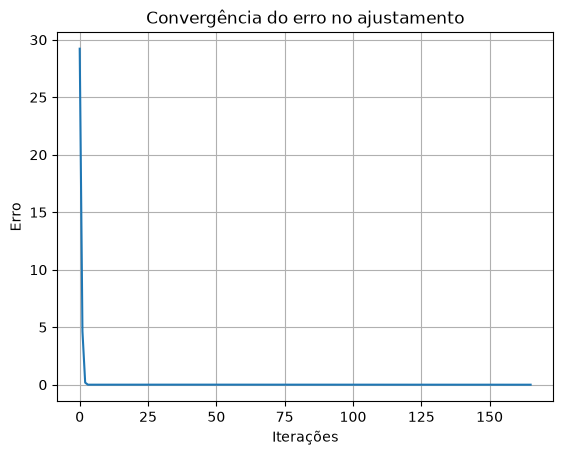

In [ ]:
import matplotlib.pyplot as plt 

# mount P
P = np.diag([1/2, 1/2, 1/4, 1/4, 1/2, 1/2, 1/4, 1/4])

# mount X_0
X_0 = np.array(X0, dtype=float)
print("\nXa:\n", X_0)

### Início do ajustametno 
erros = [] # guardar cada erro durante as iterações para compor um gráfico
erro = 10000000
while erro>10e-6:
    # update W_i
    w =  np.array(W.subs({Xc: X_0[0][0], Yc: X_0[1][0], r: X_0[2][0], **L0}).evalf().tolist(), dtype=float)
    # update Jacobians A e B
    a =  np.array(A.subs({Xc: X_0[0][0], Yc: X_0[1][0], r: X_0[2][0], **L0}).evalf().tolist(), dtype=float)
    b =  np.array(B.subs({Xc: X_0[0][0], Yc: X_0[1][0], r: X_0[2][0], **L0}).evalf().tolist() , dtype=float)
    # update Delta X , K e V
    BPinvBT_inv = np.linalg.inv(b @ np.linalg.inv(P) @ b.T)
    DeltaX = - np.linalg.inv(a.T @ BPinvBT_inv @ a) @ a.T @ BPinvBT_inv @ w
    # print("DeltaX:\n", DeltaX)
    K = -BPinvBT_inv @ (a @ DeltaX + w) 
    # print("K:\n", K)
    V = np.linalg.inv(P) @ b.T @ K
    # print("V:\n", V)
    # add erro a lista de erros para gráfico
    erro = np.linalg.norm(DeltaX)
    erros.append(erro)
    flag = "" if erro>10e-6 else "<<<-------------- erro<=10e-6 (FIM)"
    print("Erro:\n", erro, flag)
    # update X_0
    X_0 = DeltaX + X_0
    print("\nXa:\n", X_0)
    # update L_0
    # Correção no formato do vetor dos resíduos
    V = V.reshape(-1) # de (8,1) para (8,)
    L_0 = L_0 + V
    L0 = {"X_1": L_0[0], "Y_1": L_0[1], "X_2": L_0[2], "Y_2": L_0[3], "X_3": L_0[4], "Y_3": L_0[5], "X_4": L_0[6], "Y_4": L_0[7]}

# # Gráfico
plt.title("Convergência do erro no ajustamento")
plt.xlabel("Iterações")
plt.ylabel("Erro")
plt.grid()
plt.plot(erros)
plt.show()

5. Observações ajustadas

In [144]:
L0

{'X_1': np.float64(149.90484018940455),
 'Y_1': np.float64(58.21400754525734),
 'X_2': np.float64(201.68762188233515),
 'Y_2': np.float64(102.6261008163692),
 'X_3': np.float64(207.654723650451),
 'Y_3': np.float64(152.16246244669318),
 'X_4': np.float64(150.1932504379537),
 'Y_4': np.float64(176.6209591997295)}